In [1]:
import site
import sys
import subprocess
import os

# 1. Registrar la ruta de paquetes del usuario en el sistema
user_site = '/headless/.local/lib/python3.12/site-packages'
if os.path.exists(user_site):
    site.addsitedir(user_site)

# 2. Intentar importar; si falla, instalarlo automáticamente
try:
    from PyLTSpice import RawRead
    print('¡PyLTSpice ya estaba instalado y listo para usar!')
except ImportError:
    print('PyLTSpice no fue encontrado. Instalando automáticamente...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--user', 'PyLTSpice'])
    if os.path.exists(user_site):
        site.addsitedir(user_site)
    from PyLTSpice import RawRead
    print('¡PyLTSpice se instaló e importó correctamente!')


¡PyLTSpice ya estaba instalado y listo para usar!


In [2]:
import os
import re
import subprocess
import shutil
import concurrent.futures
import itertools
from PyLTSpice import RawRead

parametros_ldo = {}
graficas_ldo = {}

def one_pvt_parallel(netlist_path, raw_path, temp, vdd, proces):
    # Nombre de la carpeta limpio y seguro
    vdd_str = str(vdd).replace('.', '_')
    nombre_llave = f"V_{vdd_str}_T_{temp}_{proces}"
    
    parametros_ldo[nombre_llave] = {}
    graficas_ldo[nombre_llave] = {}
    
    # 1. CREAR LA CARPETA AISLADA PARA ESTE HILO
    sim_dir = os.path.join(raw_path, nombre_llave)
    os.makedirs(sim_dir, exist_ok=True)
    
    directorio_original = os.path.dirname(netlist_path)
    
    with open(netlist_path, 'r') as archivo:
        contenido = archivo.read()

    # Modificar parámetros PVT
    patron_corner = r"(\.lib\s+/foss/pdks/sky130A/libs\.tech/ngspice/sky130\.lib\.spice\s+)\w+"
    contenido = re.sub(patron_corner, rf"\g<1>{proces}", contenido)
    
    patron_temp = r"(\.option\s+temp=)[-\d\.]+"
    contenido = re.sub(patron_temp, rf"\g<1>{temp}", contenido)
    
    patron_vdd = r"(\.param\s+VDD\s*=\s*)[-\d\.]+"
    contenido = re.sub(patron_vdd, rf"\g<1>{vdd}", contenido)
    
    # ====================================================================
    # 2. REDIRIGIR LA SALIDA A LA CARPETA AISLADA (SIN COMILLAS)
    # ====================================================================
    nombres_base = [
        "LDO_tran_picos",
        "LDO_ac_estability",
        "LDO_ac_psrr",
        "LDO_dc_line",
        "LDO_dc_load"
    ]
    
    for base in nombres_base:
        # Crea la ruta absoluta: /foss/.../raw/V_1_62_T_-40_tt/LDO_tran_picos.raw
        ruta_absoluta_raw = os.path.join(sim_dir, f"{base}.raw")
        # Reemplaza en el texto el nombre corto por la ruta absoluta hacia la carpeta
        contenido = contenido.replace(f"{base}.raw", ruta_absoluta_raw)
    
    # Guardar netlist temporal en el directorio original para que lea los .include
    netlist_temp_path = os.path.join(directorio_original, f"ldo_temp_{nombre_llave}.spice")
    with open(netlist_temp_path, 'w') as archivo:
        archivo.write(contenido)

    # 3. SIMULAR
    comando = ['/foss/tools/ngspice/bin/ngspice', "-b", netlist_temp_path]
    resultado = subprocess.run(comando, capture_output=True, text=True, cwd=directorio_original)
    
    if resultado.returncode != 0:
        if os.path.exists(netlist_temp_path):
            os.remove(netlist_temp_path)
        return

    # Extraer LOG
    mi_log = resultado.stdout
    patron = r"([a-zA-Z0-9_]+)\s*=\s*([+-]?\d+\.?\d*[eE]?[+-]?\d*)"
    coincidencias = re.findall(patron, mi_log)
    
    for nombre, valor in coincidencias:
        parametros_ldo[nombre_llave][nombre.strip().lower()] = float(valor)
    
    if "tnom" in parametros_ldo[nombre_llave]:
        del parametros_ldo[nombre_llave]["tnom"]

    # 4. EXTRAER LOS DATOS DESDE LA CARPETA AISLADA
    try:
        raw_tran = RawRead(os.path.join(sim_dir, "LDO_tran_picos.raw"))
        raw_ac_stability = RawRead(os.path.join(sim_dir, "LDO_ac_estability.raw"))
        raw_ac_psrr = RawRead(os.path.join(sim_dir, "LDO_ac_psrr.raw"))
        raw_dc_line = RawRead(os.path.join(sim_dir, "LDO_dc_line.raw"))
        raw_dc_load = RawRead(os.path.join(sim_dir, "LDO_dc_load.raw"))
        
        graficas_ldo[nombre_llave]["time"] = raw_tran.get_trace("time").get_wave()
        graficas_ldo[nombre_llave]["t_vo"] = raw_tran.get_trace("v(vo)").get_wave()
        
        graficas_ldo[nombre_llave]["frecuencia"] = raw_ac_stability.get_trace("frequency").get_wave()
        graficas_ldo[nombre_llave]["fase"] = raw_ac_stability.get_trace("fase_deg").get_wave()
        graficas_ldo[nombre_llave]["ganancia"] = raw_ac_stability.get_trace("loop_gain_db").get_wave()
        
        graficas_ldo[nombre_llave]["psrr"] = raw_ac_psrr.get_trace("psrr_db").get_wave()
        
        graficas_ldo[nombre_llave]["dc_vin"] = raw_dc_line.get_trace("v(v-sweep)").get_wave()
        graficas_ldo[nombre_llave]["dc_vin_vo"] = raw_dc_line.get_trace("v(vo)").get_wave()
        
        graficas_ldo[nombre_llave]["dc_iload"] = raw_dc_load.get_trace("i(i-sweep)").get_wave()
        graficas_ldo[nombre_llave]["dc_iload_vo"] = raw_dc_load.get_trace("v(vo)").get_wave()
        
    except Exception as e:
        print(f"\n⚠️ Error al leer los datos de {nombre_llave}: {e}")

    # ====================================================================
    # 5. LIMPIEZA
    # ====================================================================
    # Borramos el netlist temporal que generó este hilo
    if os.path.exists(netlist_temp_path):
        os.remove(netlist_temp_path)
        
    # Descomenta esta línea si quieres que las carpetas se borren solas y no ocupen espacio
    # shutil.rmtree(sim_dir, ignore_errors=True)

In [3]:
import os
import re
import subprocess
import shutil
import concurrent.futures
import itertools
from PyLTSpice import RawRead

# ==============================================================================
# 3. LANZADOR MULTINÚCLEO (PARALELISMO)
# ==============================================================================
temperaturas = [-40, 27, 125]
voltajes = [1.62, 1.8, 1.98] 
corners_proceso = [
    "tt", "sf", "ff", "ss", "fs", "ll", "hh", "hl", "lh",
    "sf_ll", "sf_hh", "sf_hl", "sf_lh", "ff_ll", "ff_hh", "ff_hl", "ff_lh",
    "ss_ll", "ss_hh", "ss_hl", "ss_lh", "fs_ll", "fs_hh", "fs_hl", "fs_lh"
]

netlist_path = "/headless/.xschem/simulations/ldo_tb.spice"
raw_path = "/foss/designs/LDO-sky130/xschem/spice_raw_log/raw/"

todas_las_combinaciones = list(itertools.product(temperaturas, voltajes, corners_proceso))
total_sim = len(todas_las_combinaciones)

print(f"Lanzando {total_sim} simulaciones en PARALELO...")

# >>> IMPORTANTE: Ajusta max_workers a los núcleos físicos de tu procesador (ej. 4, 8, 16) <<<
with concurrent.futures.ThreadPoolExecutor(max_workers=8) as executor:
    futuros = [
        executor.submit(one_pvt_parallel, netlist_path, raw_path, temp, vdd, proces) 
        for temp, vdd, proces in todas_las_combinaciones
    ]
    
    completados = 0
    # as_completed nos permite actualizar la barra a medida que CUALQUIER hilo termina
    for futuro in concurrent.futures.as_completed(futuros):
        completados += 1
        print(f"Progreso global: {completados}/{total_sim} completados.", end='\r')

print("\n\n¡Simulación masiva paralela finalizada con éxito!")

Lanzando 225 simulaciones en PARALELO...
Progreso global: 225/225 completados.

¡Simulación masiva paralela finalizada con éxito!


In [4]:
import pandas as pd

# 1. Convertir el diccionario en la tabla principal
df_resultados = pd.DataFrame.from_dict(parametros_ldo, orient='index')

# 2. Calcular Mínimos, Máximos (y el promedio, que es muy útil)
# .agg(['min', 'max', 'mean']) calcula los extremos
# .T (Transponer) voltea la tabla para que sea mucho más fácil de leer
df_resumen = df_resultados.agg(['min', 'max', 'mean']).T

# 3. Mostrar la tabla resumen en la pantalla
print("--- Resumen PVT: Peor y Mejor Caso de cada Especificación ---")
display(df_resumen)

# 4. Guardar en Excel con múltiples pestañas (hojas)
try:
    # Intenta guardar en Excel (requiere la librería openpyxl)
    with pd.ExcelWriter("Reporte_Completo_LDO.xlsx") as writer:
        df_resultados.to_excel(writer, sheet_name="225_Corners")
        df_resumen.to_excel(writer, sheet_name="Resumen_Peores_Casos")
    print("\n¡Reporte exportado exitosamente a 'Reporte_Completo_LDO.xlsx'!")
    print("(Revisa la segunda hoja del Excel para ver el resumen)")
    
except ImportError:
    # Si la imagen de Docker no tiene instalado openpyxl, guarda en CSV nativo
    print("\nLibrería de Excel no detectada. Guardando como CSV...")
    df_resultados.to_csv("225_Corners_LDO.csv")
    df_resumen.to_csv("Resumen_Peores_Casos_LDO.csv")
    print("¡Tablas exportadas exitosamente a formato CSV!")

--- Resumen PVT: Peor y Mejor Caso de cada Especificación ---


,min,max,mean
temp,-40.000000,1.250000e+02,3.733333e+01
ugb,94228.100000,2.818290e+06,1.421488e+06
fase_ugb,46.880700,8.331510e+01,6.370441e+01
ganancia_banda_plana,58.858400,7.370280e+01,6.825722e+01
margen_fase,46.880700,8.331510e+01,6.370440e+01
gananciapsrr_1,30.800100,7.843380e+01,4.462366e+01
gananciapsrr_1k,30.799300,7.757740e+01,4.459866e+01
gananciapsrr_10k,30.255800,6.490110e+01,4.415507e+01
gananciapsrr_1m,29.059200,4.723120e+01,3.505110e+01
voload_max,1.190070,1.197600e+00,1.194946e+00



Librería de Excel no detectada. Guardando como CSV...
¡Tablas exportadas exitosamente a formato CSV!


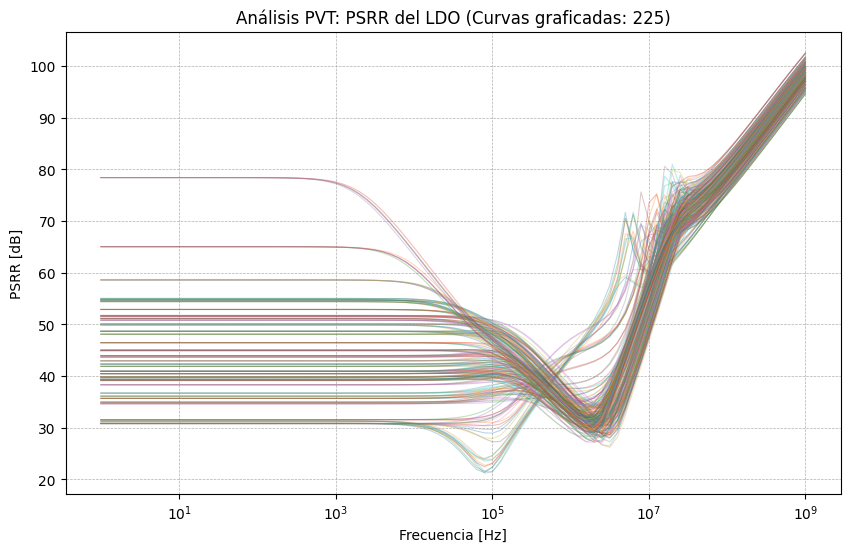

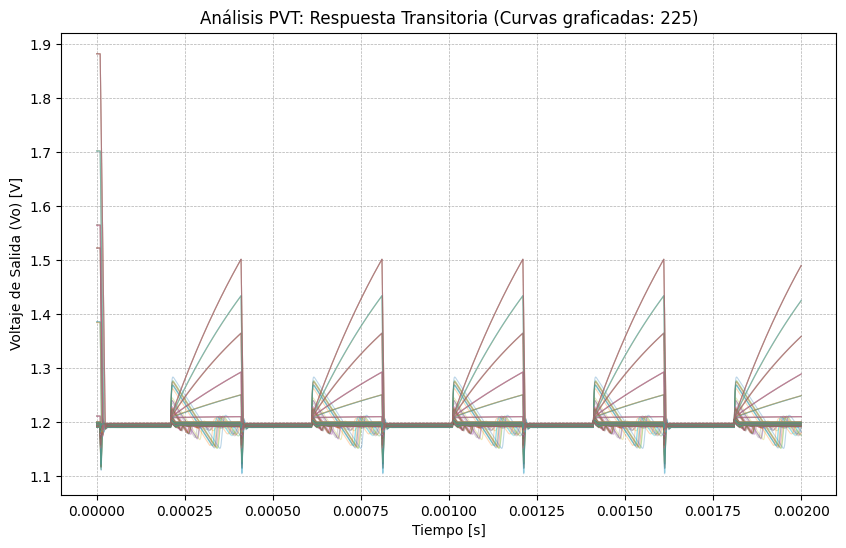

In [5]:
import matplotlib.pyplot as plt
import numpy as np

# ====================================================================
# 1. GRAFICAR PSRR (Bode - Escala Logarítmica)
# ====================================================================
plt.figure(figsize=(10, 6))
exitosas_psrr = 0

for llave, curvas in graficas_ldo.items():
    # Verificamos que la simulación tenga datos antes de extraerlos
    if "frecuencia" in curvas and "psrr" in curvas:
        x_freq = np.abs(curvas["frecuencia"])
        y_psrr = np.real(curvas["psrr"])
        
        plt.semilogx(x_freq, y_psrr, linewidth=0.8, alpha=0.3)
        exitosas_psrr += 1

plt.title(f"Análisis PVT: PSRR del LDO (Curvas graficadas: {exitosas_psrr})")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSRR [dB]")
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.savefig("psrr.png", dpi=300, bbox_inches='tight')
plt.show()

# ====================================================================
# 2. GRAFICAR RESPUESTA TRANSITORIA (Undershoot / Overshoot)
# ====================================================================
plt.figure(figsize=(10, 6))
exitosas_tran = 0

for llave, curvas in graficas_ldo.items():
    if "time" in curvas and "t_vo" in curvas:
        x_time = np.real(curvas["time"])
        y_vo = np.real(curvas["t_vo"])
        
        plt.plot(x_time, y_vo, linewidth=0.8, alpha=0.3)
        exitosas_tran += 1

plt.title(f"Análisis PVT: Respuesta Transitoria (Curvas graficadas: {exitosas_tran})")
plt.xlabel("Tiempo [s]")
plt.ylabel("Voltaje de Salida (Vo) [V]")
plt.grid(True, linestyle="--", linewidth=0.5)
plt.savefig("tran.png", dpi=300, bbox_inches='tight')
plt.show()


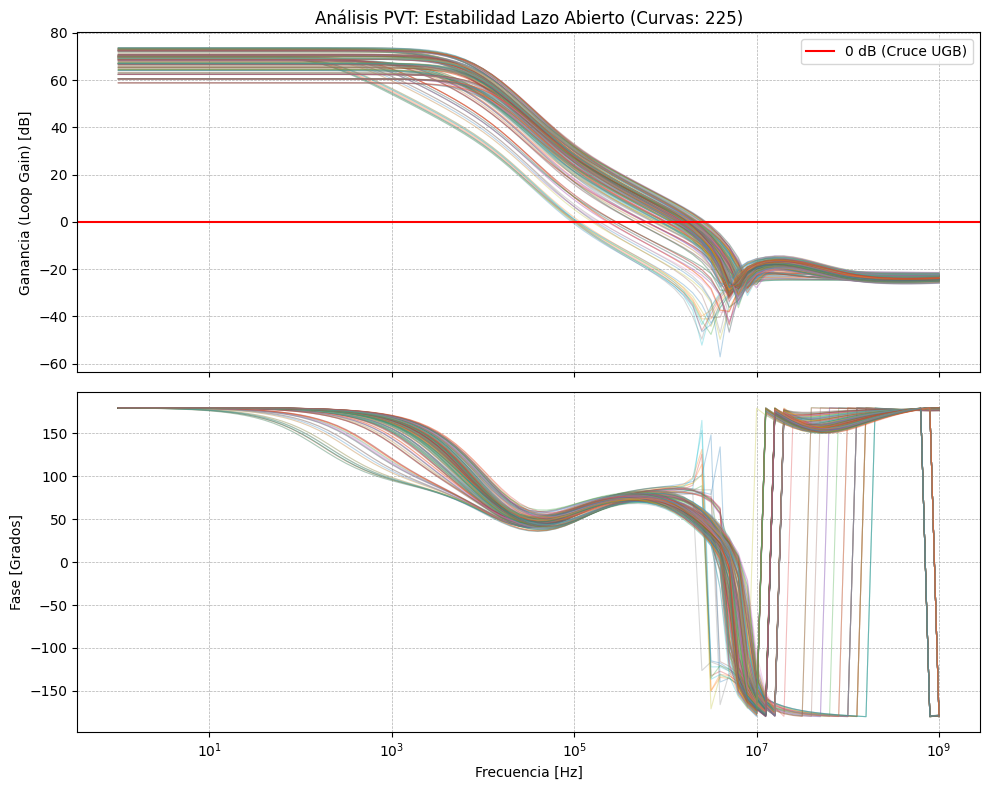

In [6]:
# ====================================================================
# 3. GRAFICAR ESTABILIDAD (Bode: Ganancia de Lazo y Margen de Fase)
# ====================================================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
exitosas_estab = 0

for llave, curvas in graficas_ldo.items():
    # Verificamos que las llaves existan en el diccionario
    if "frecuencia" in curvas and "ganancia" in curvas and "fase" in curvas:
        x_freq = np.abs(curvas["frecuencia"])
        y_gain = np.real(curvas["ganancia"])
        y_phase = np.real(curvas["fase"])
        
        # Graficamos ambas (el eje X lo comparten)
        ax1.semilogx(x_freq, y_gain, linewidth=0.8, alpha=0.3)
        ax2.semilogx(x_freq, y_phase, linewidth=0.8, alpha=0.3)
        
        exitosas_estab += 1

# --- Configuración de la gráfica de Ganancia ---
ax1.set_title(f"Análisis PVT: Estabilidad Lazo Abierto (Curvas: {exitosas_estab})")
ax1.set_ylabel("Ganancia (Loop Gain) [dB]")
ax1.grid(True, which="both", linestyle="--", linewidth=0.5)
ax1.axhline(0, color='red', linestyle='-', linewidth=1.5, label="0 dB (Cruce UGB)")
ax1.legend(loc="upper right")

# --- Configuración de la gráfica de Fase ---
ax2.set_xlabel("Frecuencia [Hz]")
ax2.set_ylabel("Fase [Grados]")
ax2.grid(True, which="both", linestyle="--", linewidth=0.5)
# Referencia común de margen de fase (dependiendo de cómo mida Xschem, suele ser 0 o -180)
# ax2.axhline(0, color='black', linestyle='--', linewidth=1) 

# tight_layout ajusta automáticamente los márgenes para que no se vea apretado
plt.tight_layout()
plt.savefig("estabilidad.png", dpi=300, bbox_inches='tight')
plt.show()


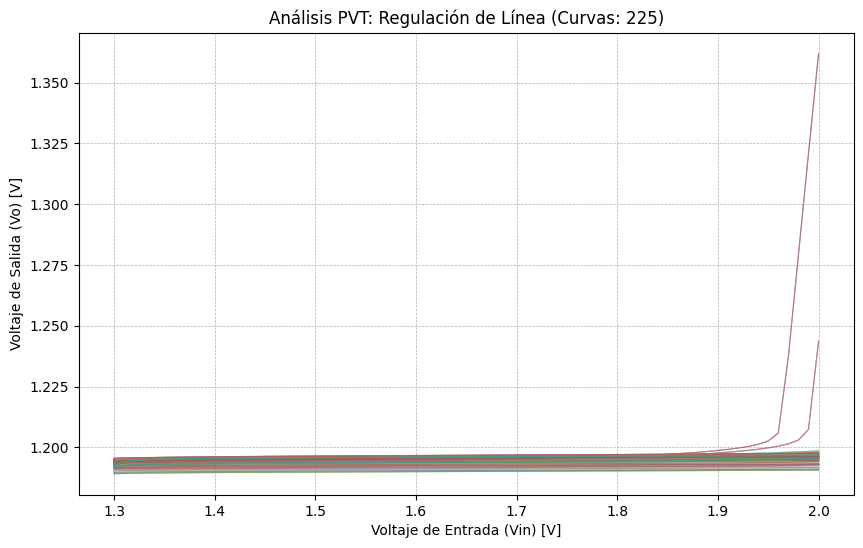

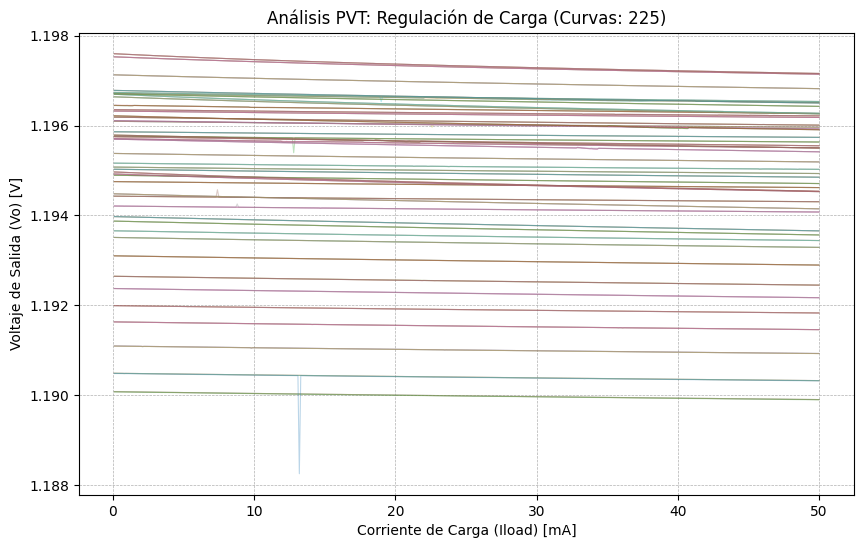

In [7]:
# ====================================================================
# 4. GRAFICAR REGULACIÓN DE LÍNEA (Vout vs Vin)
# ====================================================================
plt.figure(figsize=(10, 6))
exitosas_line = 0

for llave, curvas in graficas_ldo.items():
    if "dc_vin" in curvas and "dc_vin_vo" in curvas:
        x_vin = np.real(curvas["dc_vin"])
        y_vout_line = np.real(curvas["dc_vin_vo"])
        
        plt.plot(x_vin, y_vout_line, linewidth=0.8, alpha=0.3)
        exitosas_line += 1

plt.title(f"Análisis PVT: Regulación de Línea (Curvas: {exitosas_line})")
plt.xlabel("Voltaje de Entrada (Vin) [V]")
plt.ylabel("Voltaje de Salida (Vo) [V]")
plt.grid(True, linestyle="--", linewidth=0.5)
# Opcional: enfocar el eje Y alrededor de tu voltaje objetivo (ej. 1.2V o 1.8V)
# plt.ylim(1.15, 1.25) 
plt.savefig("grafica_regulacion_linea.png", dpi=300, bbox_inches='tight')
plt.show()

# ====================================================================
# 5. GRAFICAR REGULACIÓN DE CARGA (Vout vs Iload)
# ====================================================================
plt.figure(figsize=(10, 6))
exitosas_load = 0

for llave, curvas in graficas_ldo.items():
    if "dc_iload" in curvas and "dc_iload_vo" in curvas:
        # Multiplicamos por 1000 para pasar de Amperios a miliAmperios (mA)
        x_iload_mA = np.real(curvas["dc_iload"]) * 1000 
        y_vout_load = np.real(curvas["dc_iload_vo"])
        
        plt.plot(x_iload_mA, y_vout_load, linewidth=0.8, alpha=0.3)
        exitosas_load += 1

plt.title(f"Análisis PVT: Regulación de Carga (Curvas: {exitosas_load})")
plt.xlabel("Corriente de Carga (Iload) [mA]")
plt.ylabel("Voltaje de Salida (Vo) [V]")
plt.grid(True, linestyle="--", linewidth=0.5)
# plt.ylim(1.15, 1.25)
plt.savefig("line_regularion.png", dpi=300, bbox_inches='tight')
plt.show()
